In [2]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split

In [3]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        logical_gpus = tf.config.list_logical_devices('GPU')
        print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
    except RuntimeError as e:
        print(e)
     

1 Physical GPUs, 1 Logical GPUs


I0000 00:00:1795131815.562033     608 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


In [4]:
def plot_learning_curve(history):
    # Graficar exactitud
    plt.figure()
    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.title('accuracy Curves')
    plt.legend()
    plt.show()

    # Graficar pérdida
    plt.figure()
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss Curves')
    plt.legend()
    plt.show()

In [5]:
(X_train, y_train), (X_test_full, y_test_full) = tf.keras.datasets.fashion_mnist.load_data()

In [6]:
X_test, X_val, y_test, y_val= train_test_split(
    X_test_full, y_test_full, test_size=0.50, random_state=42
)

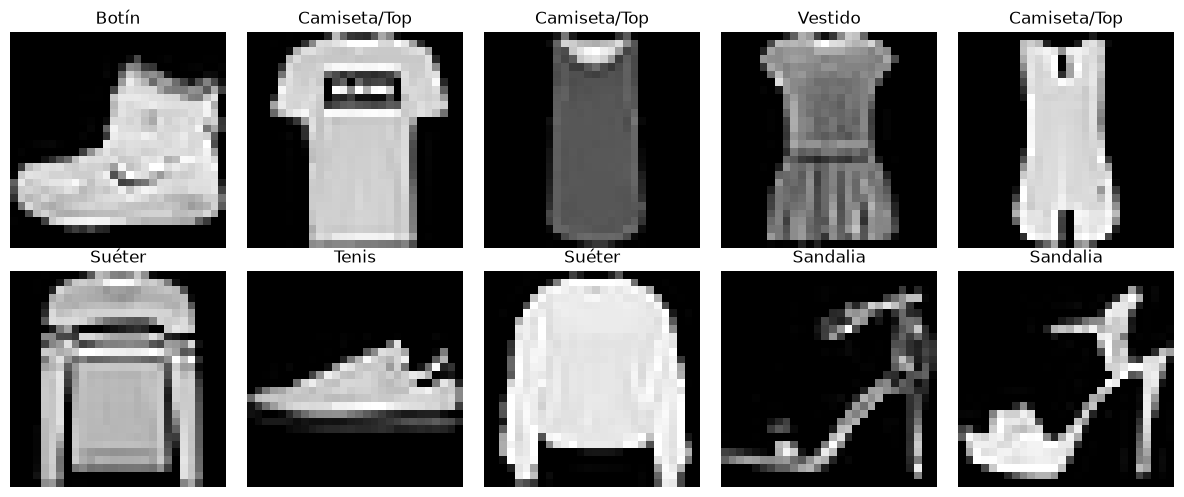

In [7]:
class_names = [
    "Camiseta/Top",  # 0: T-shirt/top
    "Pantalón",      # 1: Trouser
    "Suéter",        # 2: Pullover
    "Vestido",       # 3: Dress
    "Abrigo",        # 4: Coat
    "Sandalia",      # 5: Sandal
    "Camisa",        # 6: Shirt
    "Tenis",         # 7: Sneaker
    "Bolso",         # 8: Bag
    "Botín"          # 9: Ankle boot
]

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [8]:
X_train.shape, X_test.shape, X_val.shape

((60000, 28, 28), (5000, 28, 28), (5000, 28, 28))

In [9]:
X_train_mlp = X_train / 255.0
X_test_mlp = X_test / 255.0
X_val_mlp = X_val / 255.0

In [10]:
X_train_mlp.shape

(60000, 28, 28)

# Red con pocas capas


In [11]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_mlp.shape[1], X_train_mlp.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dense(units = 64, activation = "relu"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])


model.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history = model.fit(
    X_train_mlp,
    y_train,
    epochs = 50,
    batch_size = 32,
    validation_data = (X_val_mlp, y_val)
)

Epoch 1/50


I0000 00:00:1795131868.026100     608 service.cc:154] XLA service 0xca77d00 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795131868.026136     608 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 13.1.0[591.84.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1795131868.130346     608 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795131873.858161     608 cuda_dnn.cc:442] Loaded cuDNN version 92700


  50/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5813 - loss: 1.2654

I0000 00:00:1795131874.408415     608 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 4ms/step - accuracy: 0.8209 - loss: 0.4993 - val_accuracy: 0.8548 - val_loss: 0.4156
Epoch 2/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8651 - loss: 0.3692 - val_accuracy: 0.8644 - val_loss: 0.3729
Epoch 3/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8774 - loss: 0.3338 - val_accuracy: 0.8648 - val_loss: 0.3619
Epoch 4/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8865 - loss: 0.3076 - val_accuracy: 0.8716 - val_loss: 0.3566
Epoch 5/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8931 - loss: 0.2885 - val_accuracy: 0.8746 - val_loss: 0.3468
Epoch 6/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8981 - loss: 0.2733 - val_accuracy: 0.8786 - val_loss: 0.3477
Epoch 7/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9030 - loss: 0.2595 - val_accuracy: 0.8794 - val_loss: 0.3427
Epoch 8/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9057 - loss: 0.2484 - val_accura

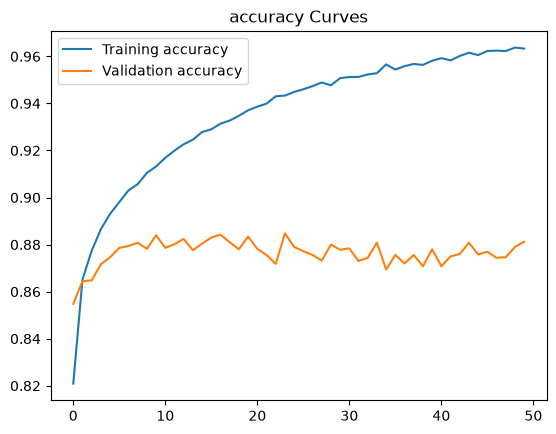

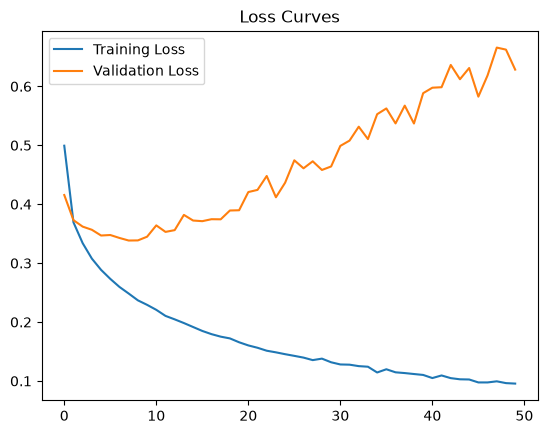

In [14]:
plot_learning_curve(history)

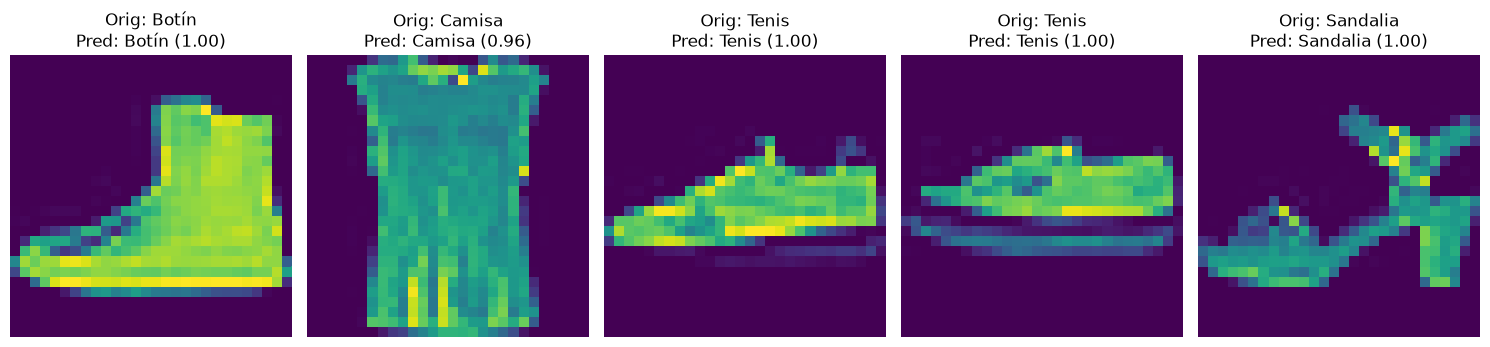

In [15]:
# Seleccionar 5 imágenes de prueba
num_images = 5
original_images = X_test_mlp[num_images:num_images+5]
original_labels = y_test[num_images:num_images+5]

# Realizar predicciones para originales y desplazadas
preds_original = model.predict(original_images, verbose=0)

# Graficar los resultados de la comparación
fig, axes = plt.subplots(1, num_images, figsize=(15, 6))

for i in range(num_images):
    # Mostrar imagen original
    axes[i].imshow(original_images[i])
    pred_orig_label = np.argmax(preds_original[i])
    pred_orig_conf = preds_original[i][pred_orig_label]
    axes[i].set_title(f"Orig: {class_names[original_labels[i]]}\nPred: {class_names[pred_orig_label]} ({pred_orig_conf:.2f})")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [39]:
model.predict(X_test_mlp[27].reshape(1,28,28), verbose=0)

array([[1.27518424e-05, 3.90782998e-06, 7.68497121e-03, 1.80639568e-14,
        9.92136240e-01, 1.04366424e-22, 1.45210041e-04, 1.34066241e-17,
        1.68811257e-05, 7.63096410e-20]], dtype=float32)

Predicción: Abrigo (99.21%)
Clase real: Abrigo


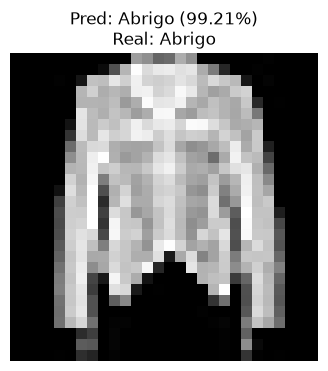

In [20]:
#Hecho con ayuda de IA.
idx = 27  # Índice del elemento en x_test que quieres evaluar

# 1. Realizar la predicción (forma (1, 10) con las probabilidades de cada clase)
probs = model.predict(X_test_mlp[idx].reshape(1, 28, 28), verbose=0)[0]

# 2. Obtener índice, nombre de la clase y probabilidad
clase_idx = np.argmax(probs)
nombre_clase = class_names[clase_idx]
probabilidad = probs[clase_idx] * 100

print(f"Predicción: {nombre_clase} ({probabilidad:.2f}%)")
print(f"Clase real: {class_names[y_test[idx]]}")

# 3. Visualizar la imagen con ambos resultados en el título
plt.figure(figsize=(4, 4))
plt.imshow(X_test_mlp[idx].squeeze(), cmap="gray")
plt.title(f"Pred: {nombre_clase} ({probabilidad:.2f}%)\nReal: {class_names[y_test[idx]]}")
plt.axis("off")
plt.show()

# Red convolucional

In [23]:
model_conv = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_mlp.shape[1], X_train_mlp.shape[2],1)),

    tf.keras.layers.Conv2D(32, (3, 3), padding = "same", activation = "relu"),
    tf.keras.layers.MaxPool2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), padding = "same", activation = "relu"),
    tf.keras.layers.MaxPool2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), padding = "same", activation = "relu"),
    tf.keras.layers.MaxPool2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 64, activation = "relu"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])


model_conv.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [31]:
model_conv.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 501,344 (1.91 MB)

 Trainable params: 167,114 (652.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 334,230 (1.27 MB)

In [24]:
history2 = model_conv.fit(
    X_train_mlp,
    y_train,
    epochs = 50,
    batch_size = 32,
    validation_data = (X_val_mlp, y_val)
)

Epoch 1/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.8359 - loss: 0.4475 - val_accuracy: 0.8826 - val_loss: 0.3118
Epoch 2/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8958 - loss: 0.2846 - val_accuracy: 0.9014 - val_loss: 0.2660
Epoch 3/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9130 - loss: 0.2370 - val_accuracy: 0.9112 - val_loss: 0.2508
Epoch 4/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9247 - loss: 0.2039 - val_accuracy: 0.9100 - val_loss: 0.2468
Epoch 5/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9366 - loss: 0.1748 - val_accuracy: 0.9150 - val_loss: 0.2457
Epoch 6/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9453 - loss: 0.1508 - val_accuracy: 0.9176 - val_loss: 0.2492
Epoch 7/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9526 - loss: 0.1294 - val_accuracy: 0.9186 - val_loss: 0.2503
Epoch 8/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9597 - loss: 0.1125 -

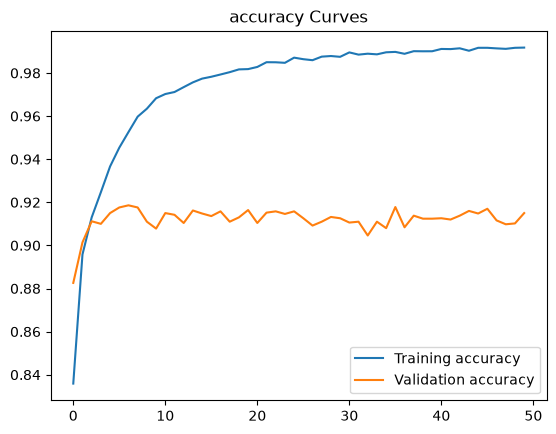

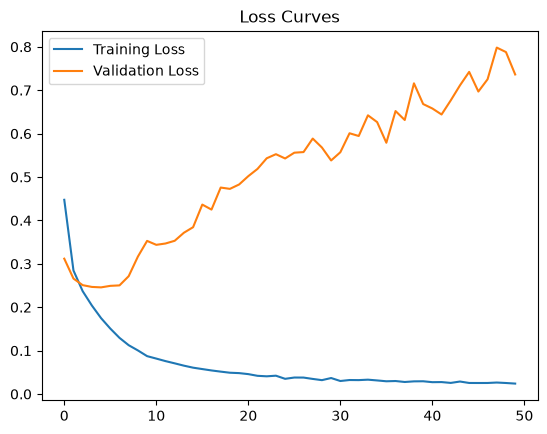

In [25]:
plot_learning_curve(history2)

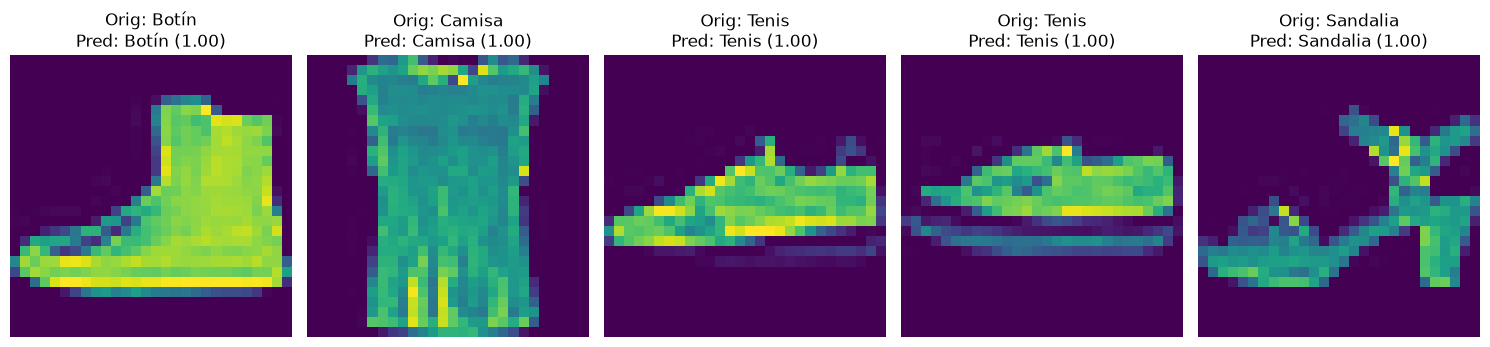

In [26]:
# Seleccionar 5 imágenes de prueba
num_images = 5
original_images = X_test_mlp[num_images:num_images+5]
original_labels = y_test[num_images:num_images+5]

# Realizar predicciones para originales y desplazadas
preds_original = model_conv.predict(original_images, verbose=0)

# Graficar los resultados de la comparación
fig, axes = plt.subplots(1, num_images, figsize=(15, 6))

for i in range(num_images):
    # Mostrar imagen original
    axes[i].imshow(original_images[i])
    pred_orig_label = np.argmax(preds_original[i])
    pred_orig_conf = preds_original[i][pred_orig_label]
    axes[i].set_title(f"Orig: {class_names[original_labels[i]]}\nPred: {class_names[pred_orig_label]} ({pred_orig_conf:.2f})")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [27]:
model_conv.predict(X_test_mlp[97].reshape(1,28,28), verbose=0)

array([[0., 1., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

Predicción: Pantalón (100.00%)
Clase real: Pantalón


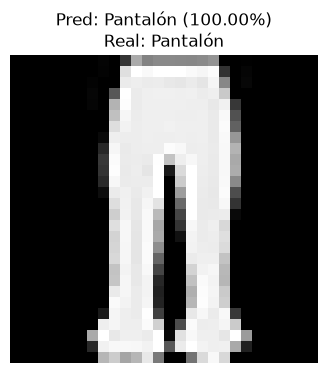

In [28]:
#Hecho con ayuda de IA.
idx = 97  # Índice del elemento en x_test que quieres evaluar

# 1. Realizar la predicción (forma (1, 10) con las probabilidades de cada clase)
probs = model_conv.predict(X_test_mlp[idx].reshape(1, 28, 28), verbose=0)[0]

# 2. Obtener índice, nombre de la clase y probabilidad
clase_idx = np.argmax(probs)
nombre_clase = class_names[clase_idx]
probabilidad = probs[clase_idx] * 100

print(f"Predicción: {nombre_clase} ({probabilidad:.2f}%)")
print(f"Clase real: {class_names[y_test[idx]]}")

# 3. Visualizar la imagen con ambos resultados en el título
plt.figure(figsize=(4, 4))
plt.imshow(X_test_mlp[idx].squeeze(), cmap="gray")
plt.title(f"Pred: {nombre_clase} ({probabilidad:.2f}%)\nReal: {class_names[y_test[idx]]}")
plt.axis("off")
plt.show()

# Red con mas capas

In [29]:
model_2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_mlp.shape[1], X_train_mlp.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dense(units = 64, activation = "relu"),
    tf.keras.layers.Dense(units = 32, activation = "relu"),
    tf.keras.layers.Dense(units = 16, activation = "relu"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])


model_2.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [30]:
model_2.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,514 (435.60 KB)

 Trainable params: 111,514 (435.60 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
history3 = model_2.fit(
    X_train_mlp,
    y_train,
    epochs = 50,
    batch_size = 32,
    validation_data = (X_val_mlp, y_val)
)

Epoch 1/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8075 - loss: 0.5421 - val_accuracy: 0.8450 - val_loss: 0.4388
Epoch 2/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8604 - loss: 0.3840 - val_accuracy: 0.8672 - val_loss: 0.3780
Epoch 3/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8734 - loss: 0.3438 - val_accuracy: 0.8666 - val_loss: 0.3745
Epoch 4/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8829 - loss: 0.3198 - val_accuracy: 0.8694 - val_loss: 0.3689
Epoch 5/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8883 - loss: 0.3024 - val_accuracy: 0.8710 - val_loss: 0.3587
Epoch 6/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8932 - loss: 0.2879 - val_accuracy: 0.8788 - val_loss: 0.3318
Epoch 7/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8972 - loss: 0.2762 - val_accuracy: 0.8740 - val_loss: 0.3445
Epoch 8/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9014 - loss: 0.2651 - 

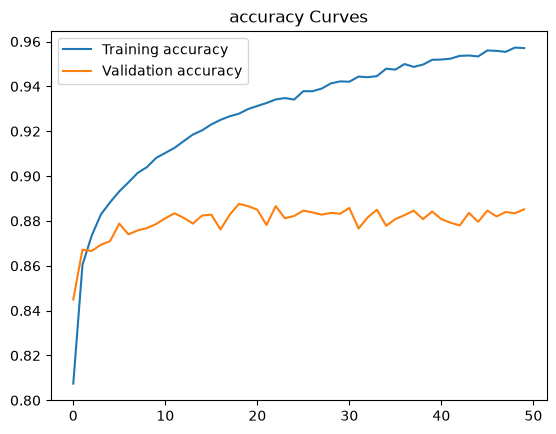

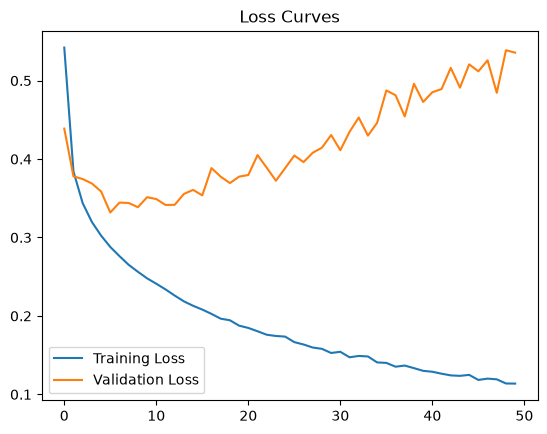

In [33]:
plot_learning_curve(history3)

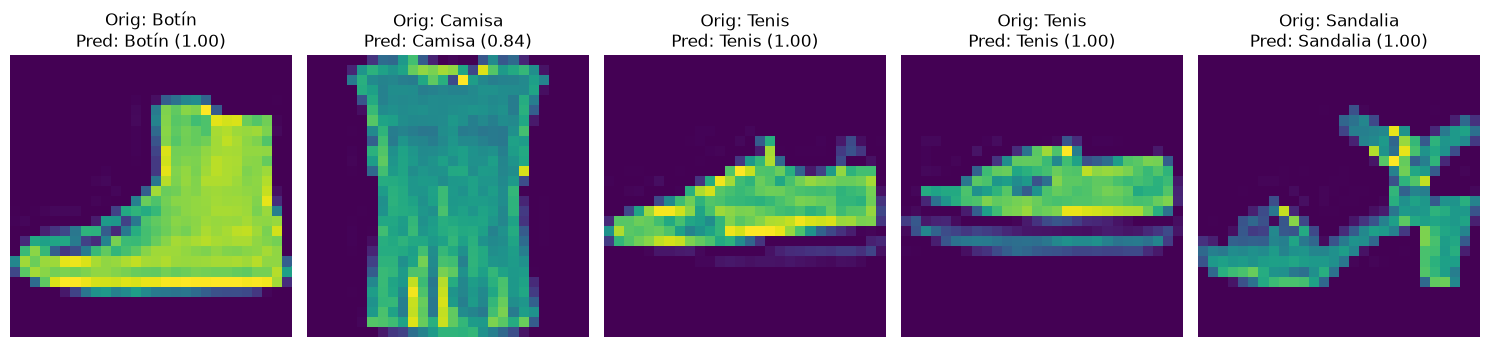

In [34]:
# Seleccionar 5 imágenes de prueba
num_images = 5
original_images = X_test_mlp[num_images:num_images+5]
original_labels = y_test[num_images:num_images+5]

# Realizar predicciones para originales y desplazadas
preds_original = model_2.predict(original_images, verbose=0)

# Graficar los resultados de la comparación
fig, axes = plt.subplots(1, num_images, figsize=(15, 6))

for i in range(num_images):
    # Mostrar imagen original
    axes[i].imshow(original_images[i])
    pred_orig_label = np.argmax(preds_original[i])
    pred_orig_conf = preds_original[i][pred_orig_label]
    axes[i].set_title(f"Orig: {class_names[original_labels[i]]}\nPred: {class_names[pred_orig_label]} ({pred_orig_conf:.2f})")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [41]:
model_2.predict(X_test_mlp[49].reshape(1,28,28), verbose=0)

array([[1.9113782e-20, 6.5499237e-19, 6.9370746e-26, 1.1949667e-25,
        3.4807559e-15, 1.1328838e-07, 1.9093414e-16, 9.9999988e-01,
        2.7446027e-14, 5.9777205e-09]], dtype=float32)

Predicción: Tenis (100.00%)
Clase real: Tenis


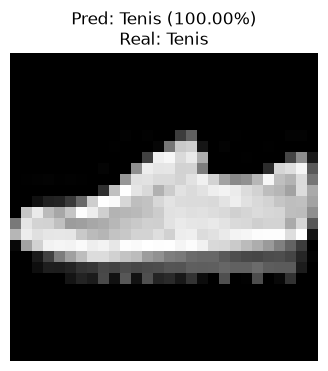

In [42]:
#Hecho con ayuda de IA.
idx = 49  # Índice del elemento en x_test que quieres evaluar

# 1. Realizar la predicción (forma (1, 10) con las probabilidades de cada clase)
probs = model_2.predict(X_test_mlp[idx].reshape(1, 28, 28), verbose=0)[0]

# 2. Obtener índice, nombre de la clase y probabilidad
clase_idx = np.argmax(probs)
nombre_clase = class_names[clase_idx]
probabilidad = probs[clase_idx] * 100

print(f"Predicción: {nombre_clase} ({probabilidad:.2f}%)")
print(f"Clase real: {class_names[y_test[idx]]}")

# 3. Visualizar la imagen con ambos resultados en el título
plt.figure(figsize=(4, 4))
plt.imshow(X_test_mlp[idx].squeeze(), cmap="gray")
plt.title(f"Pred: {nombre_clase} ({probabilidad:.2f}%)\nReal: {class_names[y_test[idx]]}")
plt.axis("off")
plt.show()